# پیش‌بینی بازه قیمت با احتمال (Quantile Forecasting) — BTC, ETH, SOL, BNB, XRP

**هدف این نوت‌بوک:** به‌جای اینکه بگوییم «قیمت هفته بعد X می‌شود»، مدل یک **توزیع** می‌دهد:

- «با ۹۰٪ احتمال، بازده ۷ روز آینده بین a و b است»
- «احتمال اینکه قیمت در طول هفته حداقل یک بار ۱۰٪ پایین بیاید چقدر است» (برای اهرم و لیکوئید شدن مهم است)
- و از روی همین احتمال‌ها، یک **ایجنت ساده** حداکثر اهرم امن و اندازه پوزیشن را حساب می‌کند.

**چه چیزهایی نسبت به test1 و test2 عوض شده:**

1. **هدف:** سه چیز پیش‌بینی می‌شود، هر کدام با ۱۱ چندک (۱٪ تا ۹۹٪):
   - `ret`: بازده لگاریتمی ۷ روزه (قیمت پایان هفته)
   - `pmin`: پایین‌ترین قیمت در طول ۷ روز (برای ریسک لیکوئید شدن پوزیشن خرید)
   - `pmax`: بالاترین قیمت در طول ۷ روز (برای ریسک پوزیشن فروش)
2. **مدل:** LightGBM با `objective='quantile'`، یک مدل مشترک برای هر ۵ ارز (داده ۵ برابر). هدف بر نوسان تقسیم می‌شود تا ارزها قابل مقایسه شوند.
3. **کالیبره کردن:** چندک‌ها با خطاهای واقعی ۳۶۵ روز گذشته تنظیم می‌شوند تا «بازه ۹۰٪» واقعاً ۹۰٪ وقت‌ها درست باشد.
4. **مبناهای ساده (Baseline):** چندک تاریخی، FHS (نوسان EWMA × توزیع تاریخی) و GARCH-t. مدل فقط وقتی ارزش دارد که از این‌ها بهتر باشد.
5. **ارزیابی با معیار احتمالاتی، نه سود:** Pinball loss، CRPS، پوشش بازه‌ها و نمودار کالیبراسیون.
6. **دوره تست قفل است:** از ۲۰۲۶-۰۱-۰۱ به بعد فقط یک بار و در انتهای کار دیده می‌شود (`RUN_FINAL_TEST`).
7. **ویژگی‌های جدید:** نوسان محقق‌شده ۵ دقیقه‌ای (HAR)، semivariance، سهم جهش‌ها، funding rate بازار آتی و نوسان ضمنی Deribit (DVOL).
8. **CEBRA حذف شده،** چون در هر دو تست قبلی چیزی اضافه نکرد.

**نحوه اجرا:** `Runtime → Run all`. به GPU نیازی نیست. اجرای اول برای دانلود داده دقیقه‌ای حدود ۲۰ تا ۴۰ دقیقه طول می‌کشد. بعد از آن همه چیز از cache خوانده می‌شود. اگر `USE_DRIVE=True` باشد، cache روی Google Drive می‌ماند.

> هشدار: هیچ‌کدام از اعداد این نوت‌بوک وعده سود نیست. قبل از پول واقعی، حتماً paper trading کنید.

## ۰) نصب کتابخانه‌ها

In [1]:
%pip -q install "lightgbm>=4.3" "arch>=7.0" pyarrow requests tqdm

## ۱) تنظیمات

همه پارامترها اینجاست. **پارامترهای مدل را بر اساس نتیجه دوره تست عوض نکنید.** فقط بر اساس دوره توسعه (dev) تصمیم بگیرید.

In [2]:
import io, os, json, time, zipfile, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import lightgbm as lgb
from arch import arch_model
from scipy import stats
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ---------------- data ----------------
SYMBOLS = ['BTC', 'ETH', 'SOL', 'BNB', 'XRP']
PAIRS = {s: s + 'USDT' for s in SYMBOLS}
DATA_START = '2020-01'          # first month to download (SOL starts later, handled automatically)
USE_FUNDING = True              # Binance USD-M perpetual funding rates (data.binance.vision)
USE_DVOL = True                 # Deribit implied-volatility index (BTC, ETH)
USE_DRIVE = False               # True = keep the cache on Google Drive

# ---------------- forecasting ----------------
HORIZON = 7                     # days ahead
QUANTILES = np.array([0.01, 0.025, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.975, 0.99])
TARGETS = ['ret', 'pmin', 'pmax']
MIN_VALID_MINUTES = 1200        # a day with fewer 1m candles is treated as missing
DEV_FIRST = '2022-01-01'        # first out-of-sample forecast in the development period
TEST_START = '2026-01-01'       # LOCKED test period starts here
RUN_FINAL_TEST = False          # set True ONCE, at the very end, after all choices are frozen
SEED = 42
# Fixed in advance (not tuned on the test period). Many trees + small learning rate,
# no early stopping on a tiny noisy validation window (that is why test1/test2 stopped at 1 tree).
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, max_depth=5,
                  min_child_samples=150, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=5.0, n_jobs=-1, random_state=SEED, verbose=-1)
RECAL_WINDOW_DAYS = 365         # rolling recalibration window (uses only resolved past forecasts)
RECAL_MIN_ROWS = 300

# ---------------- agent / leverage demo ----------------
FEE_PER_SIDE = 0.0005           # perpetual taker fee
MMR = 0.005                     # maintenance margin rate (approximate)
LIQ_PROB_MAX = 0.01             # max allowed probability of liquidation per holding period
KELLY_FRACTION = 0.25           # fractional Kelly
MAX_LEVERAGE = 5.0
ALLOW_SHORT = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/quantile_crypto')
else:
    ROOT = Path('/content/quantile_crypto') if Path('/content').exists() else Path('quantile_crypto')
CACHE = ROOT / 'minute_daily'
AUX = ROOT / 'aux'
RESULTS = ROOT / 'results'
for p in (CACHE, AUX, RESULTS):
    p.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
TODAY = pd.Timestamp.now(tz='UTC').normalize()
print('Today (UTC):', TODAY.date(), '| cache:', ROOT)
print('Quantiles:', QUANTILES.tolist())

Today (UTC): 2026-11-18 | cache: /content/quantile_crypto
Quantiles: [0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.975, 0.99]


## ۲) دانلود داده ۱ دقیقه‌ای بایننس و خلاصه‌کردن آن به ویژگی‌های روزانه

برای هر ماه یک فایل ZIP از `data.binance.vision` دانلود و همان لحظه به یک ردیف روزانه تبدیل می‌شود. فایل خام نگه داشته نمی‌شود. از داده دقیقه‌ای این‌ها ساخته می‌شود:

- `rv5`: نوسان محقق‌شده با بازده‌های ۵ دقیقه‌ای (بهترین تخمین نوسان واقعی روز)
- `rv1`: همین با بازده ۱ دقیقه‌ای (نسبتش با rv5 نویز بازار را نشان می‌دهد)
- `rs_neg`: سهم نوسان منفی (semivariance)
- `bpv`: bipower variation (تفاوتش با rv یعنی جهش قیمت)
- `max_abs_r1m`: بزرگ‌ترین حرکت یک‌دقیقه‌ای روز
- حجم، تعداد معاملات و نسبت خرید taker

ماه جاری از فایل‌های روزانه خوانده می‌شود تا پیش‌بینی زنده تا دیروز به‌روز باشد. timestampهای ۲۰۲۵ به بعد میکروثانیه‌اند و خودکار تشخیص داده می‌شوند.

In [3]:
BASE = 'https://data.binance.vision/data'
SESSION = requests.Session()

def fetch(url, tries=5, params=None):
    """GET with retries. Returns bytes, or None on 404."""
    for k in range(tries):
        try:
            r = SESSION.get(url, params=params, timeout=(20, 300))
            if r.status_code == 404:
                return None
            r.raise_for_status()
            return r.content
        except requests.RequestException:
            if k == tries - 1:
                raise
            time.sleep(2 ** k)

KCOLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time',
         'quote_volume', 'trades', 'taker_buy_base', 'taker_buy_quote', 'ignore']

def read_kline_zip(payload):
    with zipfile.ZipFile(io.BytesIO(payload)) as z:
        name = [n for n in z.namelist() if n.endswith('.csv')][0]
        with z.open(name) as f:
            df = pd.read_csv(f, header=None, names=KCOLS, usecols=[0, 1, 2, 3, 4, 7, 8, 10],
                             low_memory=False)
    df['open_time'] = pd.to_numeric(df['open_time'], errors='coerce')   # a header row becomes NaN
    df = df.dropna(subset=['open_time'])
    t = df['open_time'].to_numpy(dtype=np.int64)
    t = np.where(t > 10**14, t // 1000, t)                              # microseconds (2025+) -> ms
    df['ts'] = pd.to_datetime(t, unit='ms', utc=True)
    for c in ['open', 'high', 'low', 'close', 'quote_volume', 'trades', 'taker_buy_quote']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['open', 'high', 'low', 'close'])
    df = df[(df[['open', 'high', 'low', 'close']] > 0).all(axis=1)]
    df = df.drop_duplicates('ts').sort_values('ts')
    return df[['ts', 'open', 'high', 'low', 'close', 'quote_volume', 'trades', 'taker_buy_quote']]

def minutes_to_daily(m):
    m = m.set_index('ts')
    day = m.index.floor('D')
    g = m.groupby(day)
    d = pd.DataFrame({
        'open': g['open'].first(), 'high': g['high'].max(), 'low': g['low'].min(),
        'close': g['close'].last(), 'quote_volume': g['quote_volume'].sum(),
        'trades': g['trades'].sum(), 'taker_buy_quote': g['taker_buy_quote'].sum(),
        'n_min': g['close'].size(),
    })
    # 1-minute log returns (first minute of a day uses its own open)
    lc = np.log(m['close'])
    r1 = lc.groupby(day).diff()
    r1 = r1.fillna(np.log(m['close'] / m['open']))
    d['rv1'] = (r1 ** 2).groupby(day).sum()
    d['max_abs_r1m'] = r1.abs().groupby(day).max()
    # 5-minute returns
    c5 = m['close'].resample('5min').last().dropna()
    r5 = np.log(c5).diff().dropna()
    d5 = r5.index.floor('D')
    d['rv5'] = (r5 ** 2).groupby(d5).sum()
    d['rs_neg'] = (r5.clip(upper=0) ** 2).groupby(d5).sum()
    a = r5.abs()
    d['bpv'] = (np.pi / 2) * (a * a.shift(1)).groupby(d5).sum()
    d.index.name = 'date'
    return d

def month_daily(pair, month):
    """Daily features of one month from the monthly 1m archive (cached). None if not published."""
    path = CACHE / f'{pair}_{month}.parquet'
    if path.exists():
        return pd.read_parquet(path)
    payload = fetch(f'{BASE}/spot/monthly/klines/{pair}/1m/{pair}-1m-{month}.zip')
    if payload is None:
        return None
    d = minutes_to_daily(read_kline_zip(payload))
    d.to_parquet(path)
    return d

def day_daily(pair, day):
    """Daily features from a single daily 1m archive (used for the current / just-finished month)."""
    tag = day.strftime('%Y-%m-%d')
    path = CACHE / f'{pair}_day_{tag}.parquet'
    if path.exists():
        return pd.read_parquet(path)
    payload = fetch(f'{BASE}/spot/daily/klines/{pair}/1m/{pair}-1m-{tag}.zip')
    if payload is None:
        return None
    d = minutes_to_daily(read_kline_zip(payload))
    d.to_parquet(path)
    return d

def load_symbol(symbol):
    pair = PAIRS[symbol]
    months = pd.period_range(DATA_START, TODAY.strftime('%Y-%m'), freq='M')
    recent = set(months[-2:])
    parts, started, missing_after_listing = [], False, []
    for mth in tqdm(months, desc=pair, leave=False):
        d = month_daily(pair, str(mth))
        if d is None and mth in recent:
            # monthly file not published yet -> daily files up to yesterday
            first_day = mth.start_time.tz_localize('UTC')
            last_day = min(mth.end_time.tz_localize('UTC').normalize(), TODAY - pd.Timedelta(days=1))
            days = pd.date_range(first_day, last_day, freq='D') if last_day >= first_day else []
            dd = [day_daily(pair, dday) for dday in days]
            dd = [x for x in dd if x is not None]
            d = pd.concat(dd) if dd else None
        if d is None:
            if started:
                missing_after_listing.append(str(mth))
            continue
        started = True
        parts.append(d)
    if missing_after_listing:
        print(f'WARNING {pair}: missing months after listing: {missing_after_listing}')
    d = pd.concat(parts)
    d = d[~d.index.duplicated(keep='last')].sort_index()
    full = pd.date_range(d.index.min(), d.index.max(), freq='D')
    d = d.reindex(full)
    d.index.name = 'date'
    bad = d['n_min'].fillna(0) < MIN_VALID_MINUTES
    d.loc[bad, :] = np.nan            # incomplete day -> missing (never invented)
    return d

DAILY = {}
for s in SYMBOLS:
    DAILY[s] = load_symbol(s)
    d = DAILY[s]
    print(f"{s}: {d.index.min().date()} -> {d.index.max().date()} | days={len(d)} "
          f"| missing/incomplete days={int(d['close'].isna().sum())}")

BTCUSDT:   0%|          | 0/83 [00:00<?, ?it/s]

BTC: 2020-01-01 -> 2026-11-17 | days=2513 | missing/incomplete days=3


ETHUSDT:   0%|          | 0/83 [00:00<?, ?it/s]

ETH: 2020-01-01 -> 2026-11-17 | days=2513 | missing/incomplete days=3


SOLUSDT:   0%|          | 0/83 [00:00<?, ?it/s]

SOL: 2020-08-11 -> 2026-11-17 | days=2290 | missing/incomplete days=3


BNBUSDT:   0%|          | 0/83 [00:00<?, ?it/s]

BNB: 2020-01-01 -> 2026-11-17 | days=2513 | missing/incomplete days=3


XRPUSDT:   0%|          | 0/83 [00:00<?, ?it/s]

XRP: 2020-01-01 -> 2026-11-17 | days=2513 | missing/incomplete days=3


## ۳) داده‌های کمکی: funding rate و نوسان ضمنی (DVOL)

- **Funding rate** بازار آتی دائمی بایننس نشان می‌دهد معامله‌گرهای اهرمی چقدر یک‌طرفه شده‌اند. funding خیلی مثبت یعنی بیشتر خرید با اهرم، که معمولاً ریسک ریزش ناگهانی را بالا می‌برد. در بک‌تست ایجنت، همین funding به‌عنوان هزینه نگهداری پوزیشن هم حساب می‌شود.
- **DVOL** از Deribit نوسانی است که بازار آپشن برای ۳۰ روز آینده انتظار دارد. برای پیش‌بینی پهنای بازه، معمولاً یکی از قوی‌ترین ورودی‌هاست. فقط برای BTC و ETH وجود دارد و از حدود ۲۰۲۱ شروع می‌شود. برای ارزهای دیگر DVOL بیت‌کوین به‌عنوان «نوسان بازار» استفاده می‌شود.

اگر دانلود هر کدام شکست بخورد، نوت‌بوک بدون آن ادامه می‌دهد.

In [4]:
def load_funding(pair):
    months = pd.period_range(max(DATA_START, '2019-09'), TODAY.strftime('%Y-%m'), freq='M')
    out = []
    for mth in months:
        path = AUX / f'funding_{pair}_{mth}.parquet'
        if path.exists():
            out.append(pd.read_parquet(path)['rate'])
            continue
        payload = fetch(f'{BASE}/futures/um/monthly/fundingRate/{pair}/{pair}-fundingRate-{mth}.zip')
        if payload is None:
            continue
        with zipfile.ZipFile(io.BytesIO(payload)) as z:
            with z.open([n for n in z.namelist() if n.endswith('.csv')][0]) as f:
                raw = pd.read_csv(f)
        raw.columns = [c.lower() for c in raw.columns]
        tcol = [c for c in raw.columns if 'time' in c][0]
        rcol = [c for c in raw.columns if 'rate' in c][0]
        t = pd.to_numeric(raw[tcol], errors='coerce').to_numpy(dtype=np.int64)
        t = np.where(t > 10**14, t // 1000, t)
        sr = pd.Series(pd.to_numeric(raw[rcol], errors='coerce').to_numpy(),
                       index=pd.to_datetime(t, unit='ms', utc=True).floor('D'))
        daily = sr.groupby(level=0).sum().rename('rate')
        if mth != pd.Period(TODAY.strftime('%Y-%m'), 'M'):
            daily.to_frame().to_parquet(path)
        out.append(daily)
    if not out:
        return None
    s = pd.concat(out)
    return s[~s.index.duplicated(keep='last')].sort_index()

def load_dvol(currency):
    url = 'https://www.deribit.com/api/v2/public/get_volatility_index_data'
    start = pd.Timestamp('2021-01-01', tz='UTC')
    rows = []
    edges = list(pd.date_range(start, TODAY + pd.Timedelta(days=1), freq='800D')) + [TODAY + pd.Timedelta(days=1)]
    for a, b in zip(edges[:-1], edges[1:]):
        payload = fetch(url, params=dict(currency=currency, resolution='1D',
                                         start_timestamp=int(a.timestamp() * 1000),
                                         end_timestamp=int(b.timestamp() * 1000)))
        if payload is None:
            continue
        rows += json.loads(payload)['result']['data']
    if not rows:
        return None
    df = pd.DataFrame(rows, columns=['ts', 'o', 'h', 'l', 'c']).drop_duplicates('ts')
    s = pd.Series(df['c'].to_numpy(float), index=pd.to_datetime(df['ts'], unit='ms', utc=True).dt.floor('D'))
    s = s[~s.index.duplicated(keep='last')].sort_index()
    # Conservative: a candle stamped day d may close after the end of day d -> use it from d+1.
    return s.shift(1, freq='D')

FUNDING, DVOL = {}, {}
if USE_FUNDING:
    for s in SYMBOLS:
        try:
            FUNDING[s] = load_funding(PAIRS[s])
            f = FUNDING[s]
            print(f'funding {s}:', 'none' if f is None else f'{f.index.min().date()} -> {f.index.max().date()}')
        except Exception as ex:
            print(f'funding {s} failed ({ex}); continuing without it')
            FUNDING[s] = None
if USE_DVOL:
    for cur in ['BTC', 'ETH']:
        try:
            DVOL[cur] = load_dvol(cur)
            v = DVOL[cur]
            print(f'DVOL {cur}:', 'none' if v is None else f'{v.index.min().date()} -> {v.index.max().date()}')
        except Exception as ex:
            print(f'DVOL {cur} failed ({ex}); continuing without it')
            DVOL[cur] = None

funding BTC: 2020-01-01 -> 2026-10-31
funding ETH: 2020-01-01 -> 2026-10-31
funding SOL: 2020-09-13 -> 2026-10-31
funding BNB: 2020-02-10 -> 2026-10-31
funding XRP: 2020-01-06 -> 2026-10-31
DVOL BTC: 2021-03-25 -> 2026-11-19
DVOL ETH: 2021-03-25 -> 2026-11-19


## ۴) ویژگی‌ها (فقط گذشته) و هدف‌ها (آینده)

**ویژگی روز d** فقط از اطلاعاتی ساخته می‌شود که تا پایان روز d (۲۳:۵۹ UTC) معلوم است. **پیش‌بینی** در پایان روز d صادر می‌شود و درباره ۷ روز بعد است:

| هدف | تعریف |
|---|---|
| `ret` | `log(close[d+7] / close[d])`، بازده آخر هفته |
| `pmin` | `log(min(low[d+1..d+7]) / close[d])`، بدترین نقطه در طول هفته |
| `pmax` | `log(max(high[d+1..d+7]) / close[d])`، بهترین نقطه در طول هفته |

**نرمال‌سازی:** همه هدف‌ها قبل از آموزش بر `sigma_ref` تقسیم می‌شوند. `sigma_ref` نوسان EWMA تا روز d ضرب در √7 است. به این ترتیب مدل یاد می‌گیرد «چند برابر نوسان معمول» و هر ۵ ارز در یک مدل مشترک قابل استفاده می‌شوند. خروجی دوباره در `sigma_ref` ضرب می‌شود.

In [5]:
def coin_features(d, fund=None, own_iv=None, mkt_iv=None):
    f = pd.DataFrame(index=d.index)
    lc = np.log(d['close'])
    r = lc.diff()
    f['r1'], f['r3'], f['r7'], f['r30'] = r, lc.diff(3), lc.diff(7), lc.diff(30)
    rv = d['rv5']
    f['vol_d'] = 0.5 * np.log(rv)
    f['vol_w'] = 0.5 * np.log(rv.rolling(7, min_periods=5).mean())
    f['vol_m'] = 0.5 * np.log(rv.rolling(30, min_periods=20).mean())
    f['vol_q'] = 0.5 * np.log(rv.rolling(90, min_periods=60).mean())
    f['vol_trend'] = f['vol_w'] - f['vol_q']
    f['noise_ratio'] = np.log(d['rv1'] / rv)
    f['neg_share_7'] = (d['rs_neg'] / rv).rolling(7, min_periods=5).mean()
    f['jump_share_7'] = ((rv - d['bpv']).clip(lower=0) / rv).rolling(7, min_periods=5).mean()
    f['max_jump'] = d['max_abs_r1m'] / np.sqrt(rv)
    park = np.log(d['high'] / d['low']) ** 2 / (4 * np.log(2))
    f['park_w'] = 0.5 * np.log(park.rolling(7, min_periods=5).mean())
    ewvar = (r ** 2).ewm(alpha=0.06, min_periods=30, ignore_na=True).mean()
    f['ewma_vol'] = 0.5 * np.log(ewvar)
    lq, lt = np.log1p(d['quote_volume']), np.log1p(d['trades'])
    f['qv_z30'] = (lq - lq.rolling(30, min_periods=20).mean()) / lq.rolling(30, min_periods=20).std()
    f['trades_z30'] = (lt - lt.rolling(30, min_periods=20).mean()) / lt.rolling(30, min_periods=20).std()
    tbr = d['taker_buy_quote'] / d['quote_volume']
    f['taker_buy'], f['taker_buy_7'] = tbr, tbr.rolling(7, min_periods=5).mean()
    f['dd_30'] = lc - lc.rolling(30, min_periods=20).max()
    f['up_30'] = lc - lc.rolling(30, min_periods=20).min()
    f['dd_365'] = lc - lc.rolling(365, min_periods=100).max()
    if fund is not None:
        fr = fund.reindex(d.index)
        f['funding_1d'] = fr
        f['funding_7d'] = fr.rolling(7, min_periods=3).sum()
        f['funding_30d'] = fr.rolling(30, min_periods=10).mean()
    for name, iv in (('own_iv', own_iv), ('mkt_iv', mkt_iv)):
        if iv is not None:
            v = iv.reindex(d.index).ffill(limit=3)
            daily_iv = np.log(v / 100 / np.sqrt(365))
            f[name] = daily_iv
            f[name + '_minus_rv'] = daily_iv - f['vol_m']
    sigma_ref = np.sqrt(ewvar * HORIZON)
    return f, sigma_ref

def coin_targets(d):
    lc = np.log(d['close'])
    y = pd.DataFrame(index=d.index)
    y['ret'] = lc.shift(-HORIZON) - lc
    y['pmin'] = np.log(d['low']).rolling(HORIZON).min().shift(-HORIZON) - lc   # NaN if any day missing
    y['pmax'] = np.log(d['high']).rolling(HORIZON).max().shift(-HORIZON) - lc
    return y

btc_f, _ = coin_features(DAILY['BTC'])
MKT = btc_f[['r7', 'r30', 'vol_w', 'vol_m', 'ewma_vol', 'dd_30']].add_prefix('mkt_')

frames = []
for k, s in enumerate(SYMBOLS):
    d = DAILY[s]
    own_iv = DVOL.get(s) if s in ('BTC', 'ETH') else None
    f, sig = coin_features(d, FUNDING.get(s), own_iv, DVOL.get('BTC'))
    y = coin_targets(d)
    fr = FUNDING.get(s)
    fut_funding = (fr.reindex(d.index).fillna(0).rolling(HORIZON).sum().shift(-HORIZON)
                   if fr is not None else pd.Series(0.0, index=d.index))
    p = pd.concat([f, MKT.reindex(d.index)], axis=1)
    p['coin_id'] = k
    p['sigma_ref'] = sig
    p['close'] = d['close']
    p['fut_funding'] = fut_funding
    for t in TARGETS:
        p['y_' + t] = y[t]
    p['coin'] = s
    frames.append(p.reset_index())

PANEL = pd.concat(frames, ignore_index=True)
PANEL = PANEL.replace([np.inf, -np.inf], np.nan)
PANEL = PANEL[PANEL['close'].notna() & PANEL['sigma_ref'].notna() & (PANEL['sigma_ref'] > 0)]
PANEL = PANEL.sort_values(['date', 'coin_id']).reset_index(drop=True)
PANEL['label_date'] = PANEL['date'] + pd.Timedelta(days=HORIZON)   # end of this day = label known

NON_FEATURES = {'date', 'coin', 'sigma_ref', 'close', 'fut_funding', 'label_date'} | {'y_' + t for t in TARGETS}
FEATURES = [c for c in PANEL.columns if c not in NON_FEATURES]
print('rows:', len(PANEL), '| features:', len(FEATURES))
print(FEATURES)
display(PANEL.groupby('coin').agg(first=('date', 'min'), last=('date', 'max'), rows=('date', 'size'),
                                  labelled=('y_ret', lambda x: int(x.notna().sum()))))

rows: 12177 | features: 36
['r1', 'r3', 'r7', 'r30', 'vol_d', 'vol_w', 'vol_m', 'vol_q', 'vol_trend', 'noise_ratio', 'neg_share_7', 'jump_share_7', 'max_jump', 'park_w', 'ewma_vol', 'qv_z30', 'trades_z30', 'taker_buy', 'taker_buy_7', 'dd_30', 'up_30', 'dd_365', 'funding_1d', 'funding_7d', 'funding_30d', 'own_iv', 'own_iv_minus_rv', 'mkt_iv', 'mkt_iv_minus_rv', 'mkt_r7', 'mkt_r30', 'mkt_vol_w', 'mkt_vol_m', 'mkt_ewma_vol', 'mkt_dd_30', 'coin_id']


,first,last,rows,labelled
coin,,,,
BNB,2020-01-31 00:00:00+00:00,2026-11-17 00:00:00+00:00,2480,2470
BTC,2020-01-31 00:00:00+00:00,2026-11-17 00:00:00+00:00,2480,2470
ETH,2020-01-31 00:00:00+00:00,2026-11-17 00:00:00+00:00,2480,2470
SOL,2020-09-11 00:00:00+00:00,2026-11-17 00:00:00+00:00,2257,2248
XRP,2020-01-31 00:00:00+00:00,2026-11-17 00:00:00+00:00,2480,2470


## ۵) Walk-forward: آموزش فصلی، پیش‌بینی خارج از نمونه

در شروع هر فصل (از `DEV_FIRST` تا امروز):

- مدل فقط با ردیف‌هایی آموزش می‌بیند که **برچسبشان قبل از شروع فصل کامل معلوم شده** (`label_date < شروع فصل`). پس هیچ نشتی از آینده وجود ندارد.
- برای هر هدف و هر چندک یک مدل LightGBM جدا آموزش می‌بیند (۳ × ۱۱ = ۳۳ مدل در هر فصل).
- چندک‌ها در آخر مرتب می‌شوند تا هیچ‌وقت چندک ۹۰٪ زیر چندک ۷۵٪ نیفتد.

پیش‌بینی‌های دوره تست هم ساخته می‌شوند (برای پیش‌بینی زنده و کالیبره‌کردن لازم‌اند)، **ولی تا وقتی `RUN_FINAL_TEST=False` است، هیچ معیاری روی آن‌ها حساب یا نمایش داده نمی‌شود.**

In [6]:
OOS = PANEL[PANEL['date'] >= pd.Timestamp(DEV_FIRST, tz='UTC')].reset_index(drop=True)
OOS_DATES = OOS['date'].to_numpy()
K = len(QUANTILES)
PRED = {}            # PRED[model][target] -> (n_oos, K) raw log-return quantiles
SCALED = {t: np.full((len(OOS), K), np.nan) for t in TARGETS}   # LightGBM scaled output

fold_starts = pd.date_range(pd.Timestamp(DEV_FIRST, tz='UTC'), OOS['date'].max(), freq='QS')
if len(fold_starts) == 0 or fold_starts[0] > pd.Timestamp(DEV_FIRST, tz='UTC'):
    fold_starts = fold_starts.insert(0, pd.Timestamp(DEV_FIRST, tz='UTC'))
fold_ends = list(fold_starts[1:]) + [OOS['date'].max() + pd.Timedelta(days=1)]

t0 = time.time()
for T, T2 in zip(fold_starts, fold_ends):
    test_idx = np.where((OOS['date'] >= T) & (OOS['date'] < T2))[0]
    if len(test_idx) == 0:
        continue
    train_all = PANEL[PANEL['label_date'] < T]
    Xte = OOS.loc[test_idx, FEATURES]
    n_tr = {}
    for t in TARGETS:
        tr = train_all[train_all['y_' + t].notna()]
        n_tr[t] = len(tr)
        ys = (tr['y_' + t] / tr['sigma_ref']).to_numpy()
        out = np.empty((len(test_idx), K))
        for j, q in enumerate(QUANTILES):
            m = lgb.LGBMRegressor(objective='quantile', alpha=float(q), **LGB_PARAMS)
            m.fit(tr[FEATURES], ys, categorical_feature=['coin_id'])
            out[:, j] = m.predict(Xte)
        SCALED[t][test_idx] = np.sort(out, axis=1)
    print(f'fold {T.date()} -> {(T2 - pd.Timedelta(days=1)).date()}: train rows={n_tr["ret"]}, '
          f'forecast rows={len(test_idx)}  ({time.time() - t0:.0f}s)', flush=True)

sig = OOS['sigma_ref'].to_numpy()[:, None]
PRED['LGBM_Q'] = {t: SCALED[t] * sig for t in TARGETS}
print('LightGBM quantile models done.')

fold 2022-01-01 -> 2022-03-31: train rows=3218, forecast rows=450  (21s)
fold 2022-04-01 -> 2022-06-30: train rows=3668, forecast rows=455  (38s)
fold 2022-07-01 -> 2022-09-30: train rows=4123, forecast rows=460  (56s)
fold 2022-10-01 -> 2022-12-31: train rows=4583, forecast rows=460  (78s)
fold 2023-01-01 -> 2023-03-31: train rows=5043, forecast rows=450  (101s)
fold 2023-04-01 -> 2023-06-30: train rows=5493, forecast rows=455  (122s)
fold 2023-07-01 -> 2023-09-30: train rows=5948, forecast rows=460  (152s)
fold 2023-10-01 -> 2023-12-31: train rows=6408, forecast rows=460  (178s)
fold 2024-01-01 -> 2024-03-31: train rows=6868, forecast rows=455  (204s)
fold 2024-04-01 -> 2024-06-30: train rows=7323, forecast rows=455  (232s)
fold 2024-07-01 -> 2024-09-30: train rows=7778, forecast rows=460  (265s)
fold 2024-10-01 -> 2024-12-31: train rows=8238, forecast rows=460  (293s)
fold 2025-01-01 -> 2025-03-31: train rows=8698, forecast rows=450  (324s)
fold 2025-04-01 -> 2025-06-30: train rows=

### کالیبره‌کردن چندک‌ها با گذشته

برای هر روز پیش‌بینی، خطاهای پیش‌بینی‌های **۳۶۵ روز گذشته که جوابشان معلوم شده** نگاه می‌شود و هر چندک کمی جابه‌جا می‌شود تا پوشش واقعی‌اش درست شود. مثلاً اگر چندک ۵٪ در عمل ۸٪ وقت‌ها شکسته شده، کمی پایین‌تر می‌رود. این کار کاملاً causal است و فقط از گذشته استفاده می‌کند. خروجی: مدل `LGBM_Q_CAL`.

In [7]:
def recalibrate(scaled, ys_true, dates, label_dates):
    """Rolling quantile recalibration using only forecasts whose labels are already known."""
    out = np.full_like(scaled, np.nan)
    err = ys_true[:, None] - scaled
    window = np.timedelta64(RECAL_WINDOW_DAYS, 'D')
    for d in np.unique(dates):
        rows = np.where(dates == d)[0]
        lo = np.searchsorted(dates, d - window, side='left')
        hi = np.searchsorted(label_dates, d, side='right')     # label known by end of day d
        e = err[lo:hi]
        e = e[np.isfinite(e).all(axis=1)]
        if len(e) < RECAL_MIN_ROWS:
            out[rows] = scaled[rows]
            continue
        adj = np.array([np.quantile(e[:, j], QUANTILES[j]) for j in range(len(QUANTILES))])
        out[rows] = np.sort(scaled[rows] + adj, axis=1)
    return out

label_dates = OOS['label_date'].to_numpy()
PRED['LGBM_Q_CAL'] = {}
for t in TARGETS:
    ys_true = (OOS['y_' + t] / OOS['sigma_ref']).to_numpy()
    PRED['LGBM_Q_CAL'][t] = recalibrate(SCALED[t], ys_true, OOS_DATES, label_dates) * sig
print('Recalibration done.')

Recalibration done.


## ۶) مبناهای ساده (Baseline)

مدل یادگیری ماشین فقط وقتی ارزش دارد که از روش‌های ساده و شناخته‌شده **بهتر** باشد:

- **HIST:** چندک‌های بازده ۷ روزه همان ارز در ۳۶۵ روز گذشته. هیچ شرطی ندارد.
- **FHS** (Filtered Historical Simulation): نوسان فعلی (EWMA) × توزیع تاریخی بازده‌های نرمال‌شده در ۲ سال گذشته. مبنای سرسختی است.
- **GARCH_T:** مدل GARCH(1,1) با توزیع t، فصلی fit می‌شود. فقط برای `ret`.

In [8]:
def lagged_rolling_quantiles(values, window, min_periods):
    """values: per-coin daily series (full calendar). Uses only labels already known (lag HORIZON)."""
    lagged = values.shift(HORIZON)
    return np.column_stack([lagged.rolling(window, min_periods=min_periods).quantile(q).to_numpy()
                            for q in QUANTILES])

PRED['HIST'] = {t: np.full((len(OOS), K), np.nan) for t in TARGETS}
PRED['FHS'] = {t: np.full((len(OOS), K), np.nan) for t in TARGETS}
PRED['GARCH_T'] = {'ret': np.full((len(OOS), K), np.nan)}

for s in SYMBOLS:
    P = PANEL[PANEL['coin'] == s].set_index('date')
    cal = pd.date_range(P.index.min(), P.index.max(), freq='D')
    P = P.reindex(cal)
    oos_rows = np.where(OOS['coin'] == s)[0]
    pos = cal.get_indexer(OOS.loc[oos_rows, 'date'])
    for t in TARGETS:
        hist = lagged_rolling_quantiles(P['y_' + t], 365, 180)
        fhs = lagged_rolling_quantiles(P['y_' + t] / P['sigma_ref'], 730, 250) * P['sigma_ref'].to_numpy()[:, None]
        PRED['HIST'][t][oos_rows] = hist[pos]
        PRED['FHS'][t][oos_rows] = fhs[pos]
    # GARCH(1,1)-t on daily close-to-close returns, refit each quarter
    r = (np.log(DAILY[s]['close']).diff() * 100).fillna(0.0)
    r = r.iloc[1:]
    for T, T2 in zip(fold_starts, fold_ends):
        rows = oos_rows[(OOS.loc[oos_rows, 'date'] >= T).to_numpy() & (OOS.loc[oos_rows, 'date'] < T2).to_numpy()]
        if len(rows) == 0 or (r.index < T).sum() < 500:
            continue
        am = arch_model(r[r.index < T2], mean='Zero', vol='GARCH', p=1, q=1, dist='t', rescale=False)
        res = am.fit(last_obs=T, disp='off')
        fc = res.forecast(horizon=HORIZON, start=T, reindex=False, method='analytic')
        var_h = fc.variance.sum(axis=1)
        nu = float(res.params['nu'])
        z = stats.t.ppf(QUANTILES, nu) * np.sqrt((nu - 2) / nu)
        qv = np.sqrt(var_h.to_numpy())[:, None] / 100 * z[None, :]
        qv = pd.DataFrame(qv, index=var_h.index)
        PRED['GARCH_T']['ret'][rows] = qv.reindex(OOS.loc[rows, 'date']).to_numpy()

MODELS = ['HIST', 'FHS', 'GARCH_T', 'LGBM_Q', 'LGBM_Q_CAL']
print('Baselines done. Models:', MODELS)

Baselines done. Models: ['HIST', 'FHS', 'GARCH_T', 'LGBM_Q', 'LGBM_Q_CAL']


## ۷) ارزیابی روی دوره توسعه (dev) با معیارهای احتمالاتی

- **Pinball loss / CRPS:** معیار اصلی است و هرچه کمتر بهتر. هم دقت را می‌سنجد و هم باریک بودن بازه را. مدلی که بازه خیلی پهن بدهد جریمه می‌شود و مدلی که بازه خیلی باریک بدهد هم جریمه می‌شود.
- **Skill vs FHS:** چند درصد بهتر از مبنای FHS است. **فاصله اطمینان ۹۵٪** با bootstrap بلوکی ۲۸ روزه حساب می‌شود، چون پیش‌بینی‌های ۷ روزه روی هم می‌افتند. اگر فاصله اطمینان صفر را شامل شود، برتری قطعی نیست.
- **Coverage:** آیا بازه ۹۰٪ واقعاً حدود ۹۰٪ وقت‌ها درست است؟
- **Width90:** پهنای متوسط بازه ۹۰٪. بین دو مدل با پوشش درست، باریک‌تر بهتر است.

فقط ردیف‌هایی مقایسه می‌شوند که **همه مدل‌ها** برایشان پیش‌بینی دارند، تا مقایسه منصفانه باشد.

,period,target,model,rows,CRPS_x100,skill_vs_FHS_%,skill_CI95_%,cov50,cov80,cov90,cov98,width90_%
0,dev,ret,HIST,7305,3.247,3.191,"[0.4, 6.1]",0.525,0.805,0.897,0.973,32.591
1,dev,ret,FHS,7305,3.354,0.000,reference,0.496,0.792,0.889,0.975,34.294
2,dev,ret,GARCH_T,7305,3.221,3.950,"[1.8, 5.7]",0.547,0.822,0.914,0.986,34.922
3,dev,ret,LGBM_Q,7305,3.496,-4.252,"[-8.8, 0.4]",0.424,0.704,0.820,0.942,27.103
4,dev,ret,LGBM_Q_CAL,7305,3.509,-4.644,"[-10.3, 1.2]",0.490,0.785,0.885,0.969,35.091
5,dev,pmin,HIST,7305,2.432,1.503,"[-3.4, 6.0]",0.484,0.784,0.885,0.969,24.309
6,dev,pmin,FHS,7305,2.469,0.000,reference,0.484,0.785,0.884,0.971,22.876
7,dev,pmin,LGBM_Q,7305,2.615,-5.904,"[-11.6, -0.1]",0.385,0.694,0.805,0.931,20.238
8,dev,pmin,LGBM_Q_CAL,7305,2.620,-6.132,"[-12.2, 1.0]",0.478,0.782,0.884,0.967,26.371
9,dev,pmax,HIST,7305,2.141,3.264,"[-0.8, 7.8]",0.504,0.798,0.895,0.973,21.812


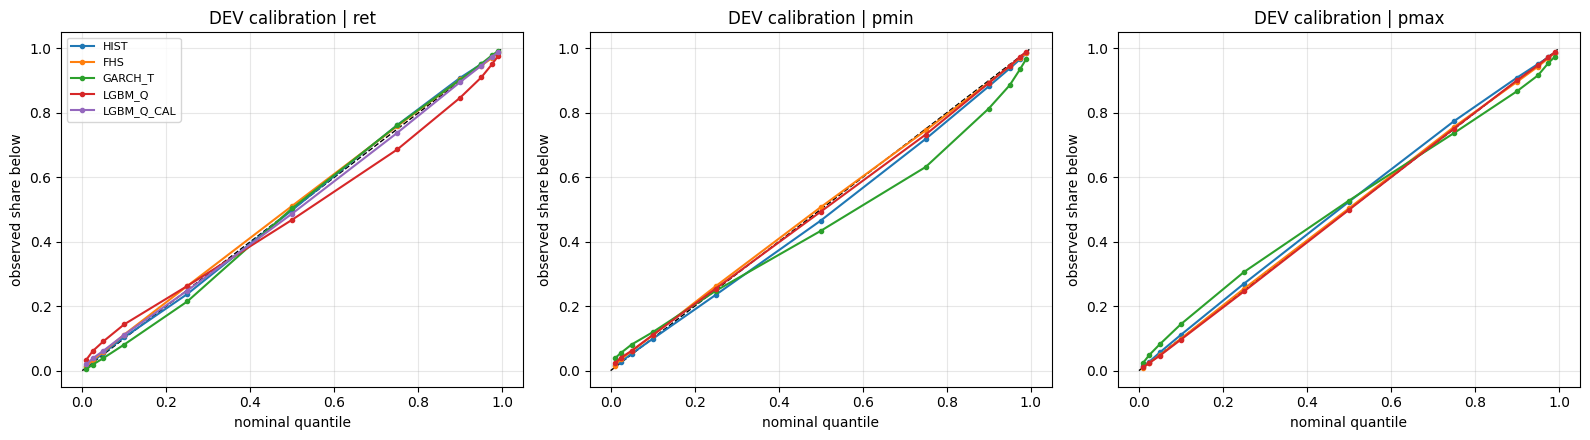

In [9]:
def pinball_matrix(y, qp):
    d = y[:, None] - qp
    return np.maximum(QUANTILES * d, (QUANTILES - 1) * d)

def models_for(t):
    return [m for m in MODELS if t in PRED[m]]

def common_mask(t, period_mask):
    y = OOS['y_' + t].to_numpy()
    m = period_mask & np.isfinite(y)
    for name in models_for(t):
        m &= np.isfinite(PRED[name][t]).all(axis=1)
    return m

def block_bootstrap_ci(diff_by_date, block=28, reps=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    x = diff_by_date.to_numpy()
    n = len(x)
    nb = int(np.ceil(n / block))
    means = []
    for _ in range(reps):
        starts = rng.integers(0, max(1, n - block + 1), nb)
        idx = np.concatenate([np.arange(s0, min(s0 + block, n)) for s0 in starts])[:n]
        means.append(x[idx].mean())
    return np.percentile(means, [2.5, 97.5])

def evaluate(period_mask, label):
    rows, calib = [], {}
    for t in TARGETS:
        m = common_mask(t, period_mask)
        if m.sum() == 0:
            continue
        y = OOS['y_' + t].to_numpy()[m]
        dates = OOS['date'].to_numpy()[m]
        ref_loss = pd.Series(pinball_matrix(y, PRED['FHS'][t][m]).mean(axis=1)).groupby(dates).mean()
        for name in models_for(t):
            qp = PRED[name][t][m]
            L = pinball_matrix(y, qp)
            loss_by_date = pd.Series(L.mean(axis=1)).groupby(dates).mean()
            crps = 2 * L.mean()
            skill = 1 - loss_by_date.mean() / ref_loss.mean()
            lo, hi = (0.0, 0.0) if name == 'FHS' else block_bootstrap_ci(loss_by_date - ref_loss)
            iq = {q: j for j, q in enumerate(QUANTILES)}
            cov = lambda a, b: float(np.mean((y >= qp[:, iq[a]]) & (y <= qp[:, iq[b]])))
            rows.append({'period': label, 'target': t, 'model': name, 'rows': int(m.sum()),
                         'CRPS_x100': 100 * crps,
                         'skill_vs_FHS_%': 100 * skill,
                         'skill_CI95_%': ('reference' if name == 'FHS' else
                                          f'[{-100 * hi / ref_loss.mean():.1f}, {-100 * lo / ref_loss.mean():.1f}]'),
                         'cov50': cov(0.25, 0.75), 'cov80': cov(0.10, 0.90),
                         'cov90': cov(0.05, 0.95), 'cov98': cov(0.01, 0.99),
                         'width90_%': 100 * float(np.mean(qp[:, iq[0.95]] - qp[:, iq[0.05]]))})
            calib[(t, name)] = (y[:, None] < qp).mean(axis=0)
    return pd.DataFrame(rows), calib

def plot_calibration(calib, title):
    fig, axes = plt.subplots(1, len(TARGETS), figsize=(16, 4.5))
    for ax, t in zip(axes, TARGETS):
        ax.plot([0, 1], [0, 1], 'k--', lw=1)
        for name in models_for(t):
            if (t, name) in calib:
                ax.plot(QUANTILES, calib[(t, name)], marker='o', ms=3, label=name)
        ax.set_title(f'{title} | {t}'); ax.set_xlabel('nominal quantile'); ax.set_ylabel('observed share below')
        ax.grid(alpha=.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout(); plt.show()

dev_mask = (OOS['date'] < pd.Timestamp(TEST_START, tz='UTC')).to_numpy()
DEV_METRICS, DEV_CALIB = evaluate(dev_mask, 'dev')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', None)
display(DEV_METRICS.round(3))
plot_calibration(DEV_CALIB, 'DEV calibration')

### انتخاب مدل (فقط با dev)

مدلی انتخاب می‌شود که میانگین CRPS نسبی‌اش روی هر سه هدف کمترین باشد. اگر مدل LightGBM از FHS بهتر نباشد، نوت‌بوک **صادقانه** FHS را انتخاب می‌کند. این خودش یک نتیجه مهم است: یعنی ویژگی‌ها هنوز چیزی به یک مدل نوسان ساده اضافه نمی‌کنند.

In [10]:
full_models = [m for m in MODELS if all(t in PRED[m] for t in TARGETS)]
score = (DEV_METRICS[DEV_METRICS['model'].isin(full_models)]
         .groupby('model')['skill_vs_FHS_%'].mean().sort_values(ascending=False))
CHOSEN = score.index[0]
print('Mean skill vs FHS over targets (dev):')
print(score.round(2).to_string())
print('\nCHOSEN MODEL (dev only):', CHOSEN)

# Experiment log: every run is recorded, so you can see how many things were tried.
cfg = {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in dict(
    SYMBOLS=SYMBOLS, DATA_START=DATA_START, HORIZON=HORIZON, QUANTILES=QUANTILES, DEV_FIRST=DEV_FIRST,
    TEST_START=TEST_START, LGB_PARAMS=LGB_PARAMS, RECAL_WINDOW_DAYS=RECAL_WINDOW_DAYS,
    FEATURES=FEATURES).items()}
CFG_HASH = hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:10]
LOG = ROOT / 'experiment_log.jsonl'
with open(LOG, 'a') as fh:
    fh.write(json.dumps({'time': str(pd.Timestamp.now(tz='UTC')), 'kind': 'dev', 'cfg_hash': CFG_HASH,
                         'chosen': CHOSEN, 'skill': score.round(3).to_dict()}) + '\n')
runs = [json.loads(x) for x in LOG.read_text().splitlines()]
print(f'\nExperiment log: {sum(r["kind"] == "dev" for r in runs)} dev runs, '
      f'{len({r["cfg_hash"] for r in runs})} distinct configs, '
      f'{sum(r["kind"] == "test" for r in runs)} test runs so far.')

Mean skill vs FHS over targets (dev):
model
HIST          2.65
FHS           0.00
LGBM_Q_CAL   -2.83
LGBM_Q       -2.84

CHOSEN MODEL (dev only): HIST

Experiment log: 1 dev runs, 1 distinct configs, 0 test runs so far.


### نمودار بادبزنی (Fan chart) بیت‌کوین

قیمت واقعی ۷ روز بعد (خط سیاه) در برابر بازه‌های ۵۰٪ و ۹۰٪ مدل انتخاب‌شده. هر نقطه در تاریخ پایان هفته رسم شده است. در یک مدل خوب، خط سیاه تقریباً ۱۰٪ وقت‌ها از بازه ۹۰٪ بیرون می‌زند. وقتی بازار آرام است بازه باریک و وقتی پرنوسان است پهن می‌شود.

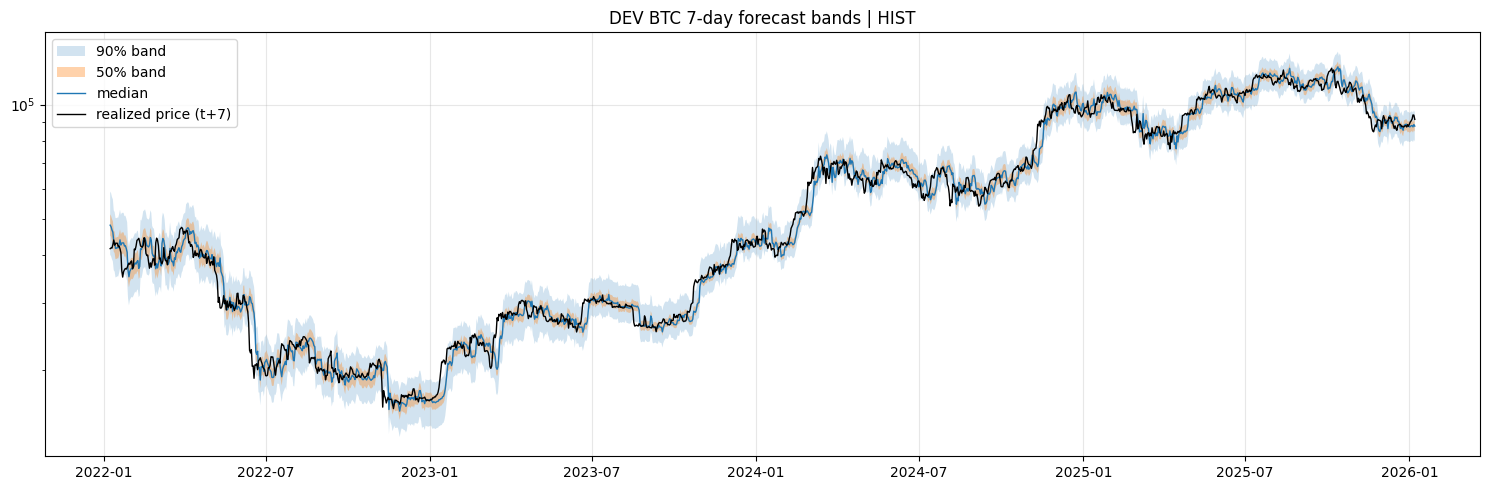

In [11]:
def fan_chart(model, coin='BTC', mask=None, title=''):
    m = (OOS['coin'] == coin).to_numpy() & (mask if mask is not None else True)
    m &= np.isfinite(PRED[model]['ret']).all(axis=1)
    sub = OOS[m]
    q = PRED[model]['ret'][m]
    iq = {q_: j for j, q_ in enumerate(QUANTILES)}
    x = sub['label_date']
    base = sub['close'].to_numpy()
    plt.figure(figsize=(15, 5))
    plt.fill_between(x, base * np.exp(q[:, iq[0.05]]), base * np.exp(q[:, iq[0.95]]), alpha=.2, label='90% band')
    plt.fill_between(x, base * np.exp(q[:, iq[0.25]]), base * np.exp(q[:, iq[0.75]]), alpha=.35, label='50% band')
    plt.plot(x, base * np.exp(q[:, iq[0.5]]), lw=1, label='median')
    realized = sub['close'] * np.exp(sub['y_ret'])
    plt.plot(x, realized, 'k', lw=1, label='realized price (t+7)')
    plt.yscale('log'); plt.title(f'{title} {coin} 7-day forecast bands | {model}')
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

fan_chart(CHOSEN, 'BTC', dev_mask, 'DEV')

## ۸) از چندک تا احتمال و اهرم (ایجنت ساده)

از ۱۱ چندک یک توزیع کامل ساخته می‌شود. بین چندک‌ها درون‌یابی خطی است و در دُم‌ها (کمتر از ۱٪ و بیشتر از ۹۹٪) احتمال به شکل نمایی کم می‌شود. با این توزیع می‌شود پرسید:

- `P(ret > +5%)`: احتمال اینکه آخر هفته ۵٪ بالاتر باشیم
- `P(pmin < x)`: احتمال اینکه قیمت در طول هفته حداقل یک بار به x برسد. **این همان احتمال لیکوئید شدن است.**

**قانون ایجنت** (قاعده‌محور و شفاف، بدون LLM):

1. از توزیع `ret` امید ریاضی μ و واریانس σ² بازده ساده حساب می‌شود. Kelly می‌گوید اندازه بهینه پوزیشن μ/σ² است و ما فقط `KELLY_FRACTION` (۲۵٪) آن را برمی‌داریم.
2. برای هر اهرم L، قیمت لیکوئید (`1/L − MMR` پایین‌تر برای خرید) و احتمال رسیدن به آن از توزیع `pmin` یا `pmax` حساب می‌شود. **بیشترین اهرمی که احتمال لیکوئیدش کمتر از `LIQ_PROB_MAX` (۱٪) باشد** سقف است.
3. اندازه نهایی = کمترینِ Kelly و سقف لیکوئید. اگر مدل مزیتی نبیند (μ نزدیک صفر)، ایجنت تقریباً بیرون می‌ماند. **این رفتار درست است، نه باگ.**

بک‌تست: هر یکشنبه ساعت ۲۳:۵۹ UTC تصمیم گرفته می‌شود و پوزیشن ۷ روز نگه داشته می‌شود. هر ارز سهم مساوی از سرمایه با isolated margin دارد. کارمزد، funding واقعی و لیکوئید شدن (از low/high واقعی دقیقه‌ای) حساب می‌شوند.

> این بک‌تست برای **انتخاب مدل استفاده نمی‌شود.** مدل فقط با CRPS انتخاب شده. اینجا فقط می‌بینیم ایجنت با این احتمال‌ها چه می‌کند.

DEV | model=HIST | weeks=209


,total_return_%,annual_%,sharpe,max_dd_%,liquidations,avg_|exposure|,weeks_long_%,weeks_short_%
AGENT,9.347,2.248,0.213,-26.806,0.0,0.402,70.335,29.665
LONG_1x_ALL,58.967,12.224,0.491,-66.123,0.0,1.000,100.000,0.000


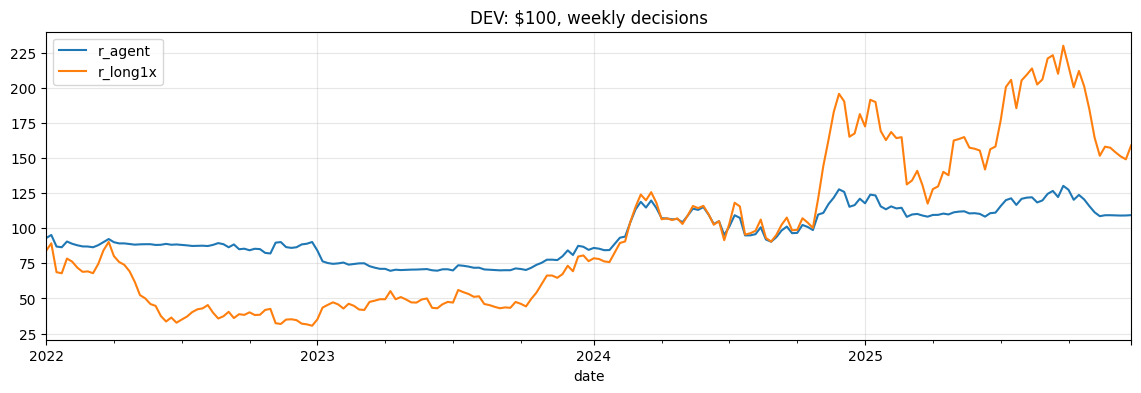

In [12]:
U_GRID = np.linspace(0.01, 0.99, 197)
LEV_GRID = np.arange(0.25, MAX_LEVERAGE + 1e-9, 0.25)

def cdf_at(qv, x):
    """P(X <= x) from sorted quantile values qv at levels QUANTILES, exponential tails."""
    Q = QUANTILES
    if x < qv[0]:
        slope = (np.log(Q[1]) - np.log(Q[0])) / max(qv[1] - qv[0], 1e-9)
        return float(Q[0] * np.exp(slope * (x - qv[0])))
    if x > qv[-1]:
        slope = (np.log(1 - Q[-2]) - np.log(1 - Q[-1])) / max(qv[-1] - qv[-2], 1e-9)
        return float(1 - (1 - Q[-1]) * np.exp(-slope * (x - qv[-1])))
    return float(np.interp(x, qv, Q))

def liq_prob(side, L, q_pmin, q_pmax):
    if side == 'long':
        if L <= 1:
            return 0.0
        return cdf_at(q_pmin, np.log(1 - (1 / L - MMR)))
    return 1 - cdf_at(q_pmax, np.log(1 + 1 / L - MMR))

def max_safe_leverage(side, q_pmin, q_pmax):
    ok = [L for L in LEV_GRID if liq_prob(side, L, q_pmin, q_pmax) <= LIQ_PROB_MAX]
    return float(max(ok)) if ok else 0.0

def agent_decision(q_ret, q_pmin, q_pmax):
    R = np.expm1(np.interp(U_GRID, QUANTILES, q_ret))
    mu, var = R.mean(), R.var()
    kelly = KELLY_FRACTION * mu / max(var, 1e-8)
    l_long = max_safe_leverage('long', q_pmin, q_pmax)
    l_short = max_safe_leverage('short', q_pmin, q_pmax) if ALLOW_SHORT else 0.0
    exposure = min(kelly, l_long) if kelly > 0 else -min(-kelly, l_short)
    return dict(exposure=exposure, mu=mu, sd=np.sqrt(var), kelly=kelly, max_long=l_long, max_short=l_short)

def sleeve_return(E, y_ret, y_pmin, y_pmax, funding):
    if E == 0:
        return 0.0, False
    L = abs(E)
    if E > 0 and L > 1 and y_pmin <= np.log(1 - (1 / L - MMR)):
        return -1.0, True
    if E < 0 and y_pmax >= np.log(1 + 1 / L - MMR):
        return -1.0, True
    r = E * np.expm1(y_ret) - 2 * FEE_PER_SIDE * L - E * funding
    return max(r, -1.0), False

def run_agent(model, period_mask, label):
    m = period_mask & (OOS['date'].dt.weekday == 6).to_numpy()
    for t in TARGETS:
        m &= np.isfinite(PRED[model][t]).all(axis=1) & OOS['y_' + t].notna().to_numpy()
    idx = np.where(m)[0]
    recs = []
    for i in idx:
        row = OOS.iloc[i]
        dec = agent_decision(PRED[model]['ret'][i], PRED[model]['pmin'][i], PRED[model]['pmax'][i])
        r_agent, liq = sleeve_return(dec['exposure'], row.y_ret, row.y_pmin, row.y_pmax, row.fut_funding)
        r_long1, _ = sleeve_return(1.0, row.y_ret, row.y_pmin, row.y_pmax, row.fut_funding)
        recs.append({'date': row.date, 'coin': row.coin, **dec, 'r_agent': r_agent, 'liquidated': liq,
                     'r_long1x': r_long1})
    tx = pd.DataFrame(recs)
    if tx.empty:
        print('no decisions in period'); return tx, None
    weekly = tx.groupby('date')[['r_agent', 'r_long1x']].mean()
    def stats_of(r):
        eq = (1 + r).cumprod()
        dd = (eq / eq.cummax() - 1).min()
        ann = eq.iloc[-1] ** (52 / len(r)) - 1
        sharpe = r.mean() / r.std() * np.sqrt(52) if r.std() > 0 else np.nan
        return {'total_return_%': 100 * (eq.iloc[-1] - 1), 'annual_%': 100 * ann,
                'sharpe': sharpe, 'max_dd_%': 100 * dd}
    summary = pd.DataFrame({
        'AGENT': {**stats_of(weekly['r_agent']), 'liquidations': int(tx['liquidated'].sum()),
                  'avg_|exposure|': tx['exposure'].abs().mean(),
                  'weeks_long_%': 100 * (tx['exposure'] > 0).mean(),
                  'weeks_short_%': 100 * (tx['exposure'] < 0).mean()},
        'LONG_1x_ALL': {**stats_of(weekly['r_long1x']), 'liquidations': 0, 'avg_|exposure|': 1.0,
                        'weeks_long_%': 100.0, 'weeks_short_%': 0.0},
    }).T
    print(f'{label} | model={model} | weeks={len(weekly)}')
    display(summary.round(3))
    eq = (1 + weekly).cumprod() * 100
    eq.plot(figsize=(14, 4), title=f'{label}: $100, weekly decisions'); plt.grid(alpha=.3); plt.show()
    return tx, summary

AGENT_DEV_TX, AGENT_DEV = run_agent(CHOSEN, dev_mask, 'DEV')

## ۹) پیش‌بینی زنده (آخرین روز موجود)

خروجی‌ای که تیم می‌خواست: برای هر ارز، بازه قیمت ۷ روز آینده، چند احتمال کلیدی و اهرم امن.

توجه: مدل آخرین فصل با داده‌های تا شروع همان فصل آموزش دیده، ولی ورودی‌ها (نوسان، funding، DVOL...) تا دیروز به‌روزند.

In [13]:
iq = {q: j for j, q in enumerate(QUANTILES)}
last = OOS['date'].max()
live_rows = []
for i in np.where(OOS['date'] == last)[0]:
    row = OOS.iloc[i]
    qr, qn, qx = (PRED[CHOSEN][t][i] for t in TARGETS)
    if not (np.isfinite(qr).all() and np.isfinite(qn).all() and np.isfinite(qx).all()):
        continue
    c = row.close
    dec = agent_decision(qr, qn, qx)
    live_rows.append({
        'coin': row.coin, 'as_of (end of day UTC)': row.date.date(), 'price': c,
        'P05': c * np.exp(qr[iq[0.05]]), 'P25': c * np.exp(qr[iq[0.25]]), 'median': c * np.exp(qr[iq[0.5]]),
        'P75': c * np.exp(qr[iq[0.75]]), 'P95': c * np.exp(qr[iq[0.95]]),
        'P(up)': 1 - cdf_at(qr, 0.0),
        'P(>+5%)': 1 - cdf_at(qr, np.log(1.05)), 'P(<-5%)': cdf_at(qr, np.log(0.95)),
        'P(touch -10%)': cdf_at(qn, np.log(0.90)), 'P(touch +10%)': 1 - cdf_at(qx, np.log(1.10)),
        'max_safe_long_lev': dec['max_long'], 'max_safe_short_lev': dec['max_short'],
        'agent_exposure': dec['exposure'],
    })
LIVE = pd.DataFrame(live_rows)
print(f'Model: {CHOSEN} | horizon: {HORIZON} days | P05..P95 = price quantiles at the end of the horizon')
display(LIVE.round(4))
LIVE.to_csv(RESULTS / 'live_forecast.csv', index=False)

Model: HIST | horizon: 7 days | P05..P95 = price quantiles at the end of the horizon


,coin,as_of (end of day UTC),price,P05,P25,median,P75,P95,P(up),P(>+5%),P(<-5%),P(touch -10%),P(touch +10%),max_safe_long_lev,max_safe_short_lev,agent_exposure
0,BTC,2026-11-17,64947.3500,57592.5948,62686.7026,64618.0673,66709.2420,70132.2427,0.4601,0.1330,0.1880,0.0974,0.0598,4.25,3.75,-0.4647
1,ETH,2026-11-17,1824.8800,1578.3186,1740.7238,1815.0511,1881.7526,2029.6823,0.4626,0.1883,0.2399,0.2119,0.1970,3.25,2.75,-0.3773
2,SOL,2026-11-17,75.1900,64.7443,71.0609,74.2476,77.8081,85.6884,0.4327,0.2132,0.2796,0.2605,0.2158,2.75,3.25,-0.3414
3,BNB,2026-11-17,597.4700,527.2995,575.4777,595.7009,614.9683,643.2542,0.4767,0.1291,0.1678,0.0936,0.0778,3.75,5.00,-0.5250
4,XRP,2026-11-17,0.9837,0.8557,0.9248,0.9618,1.0040,1.1040,0.3689,0.1658,0.3166,0.2298,0.2062,3.25,1.50,-0.4499


## ۱۰) تست نهایی (قفل) — فقط یک بار

وقتی همه تصمیم‌ها روی dev گرفته شد (ویژگی‌ها، پارامترها، مدل)، در سلول تنظیمات `RUN_FINAL_TEST = True` بگذارید و کل نوت‌بوک را دوباره اجرا کنید. **بعد از دیدن نتیجه تست، اگر چیزی را عوض کنید، دیگر تست مستقلی ندارید.** باید یک دوره جدید (مثلاً paper trading از امروز) را تست کنید. هر اجرای تست در `experiment_log.jsonl` ثبت می‌شود.

In [14]:
test_mask = (OOS['date'] >= pd.Timestamp(TEST_START, tz='UTC')).to_numpy()
if not RUN_FINAL_TEST:
    print('Test period is LOCKED. Set RUN_FINAL_TEST = True only once, after freezing every choice on dev.')
else:
    prev = [r for r in (json.loads(x) for x in LOG.read_text().splitlines()) if r['kind'] == 'test']
    if prev:
        print(f'WARNING: the test period has already been evaluated {len(prev)} time(s). '
              'It is no longer an independent test.')
    TEST_METRICS, TEST_CALIB = evaluate(test_mask, 'test')
    display(TEST_METRICS.round(3))
    plot_calibration(TEST_CALIB, 'TEST calibration')
    fan_chart(CHOSEN, 'BTC', test_mask, 'TEST')
    AGENT_TEST_TX, AGENT_TEST = run_agent(CHOSEN, test_mask, 'TEST')
    with open(LOG, 'a') as fh:
        fh.write(json.dumps({'time': str(pd.Timestamp.now(tz='UTC')), 'kind': 'test', 'cfg_hash': CFG_HASH,
                             'chosen': CHOSEN,
                             'skill': TEST_METRICS.groupby('model')['skill_vs_FHS_%'].mean().round(3).to_dict()}) + '\n')
    TEST_METRICS.to_csv(RESULTS / 'test_metrics.csv', index=False)

Test period is LOCKED. Set RUN_FINAL_TEST = True only once, after freezing every choice on dev.


## ۱۱) ذخیره خروجی‌ها و اهمیت ویژگی‌ها

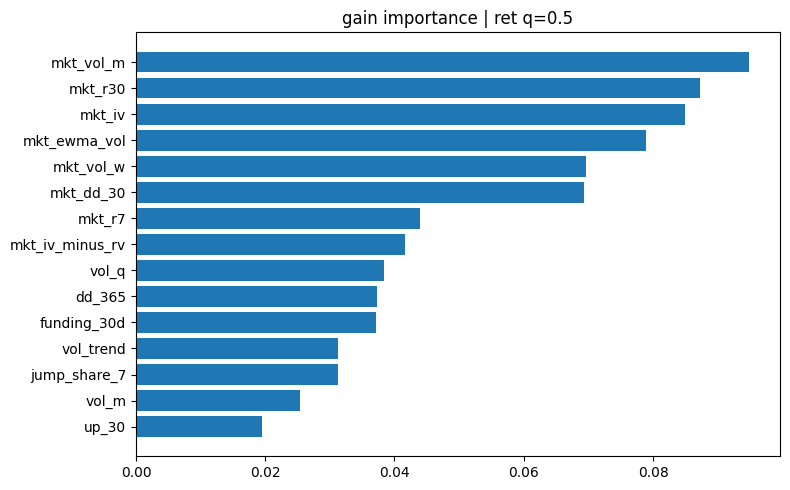

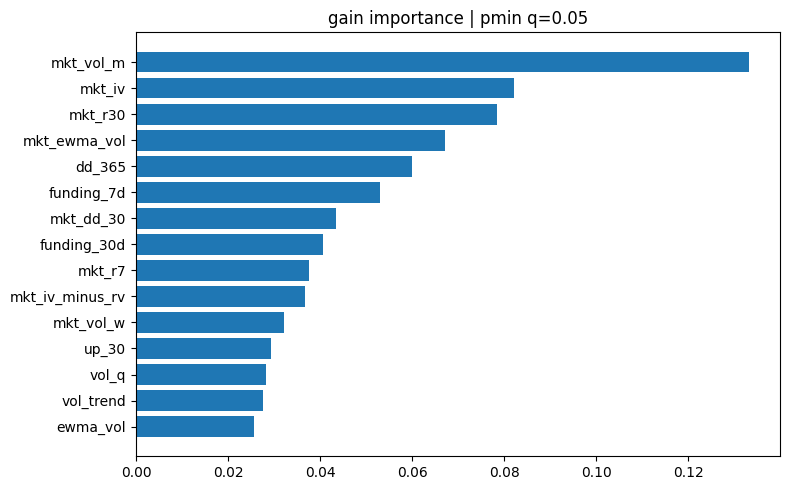

Saved to /content/quantile_crypto/results


In [15]:
DEV_METRICS.to_csv(RESULTS / 'dev_metrics.csv', index=False)
if AGENT_DEV_TX is not None and len(AGENT_DEV_TX):
    AGENT_DEV_TX.to_csv(RESULTS / 'agent_dev_decisions.csv', index=False)
out = OOS[['date', 'coin', 'close'] + ['y_' + t for t in TARGETS]].copy()
for t in TARGETS:
    for j, q in enumerate(QUANTILES):
        out[f'{CHOSEN}_{t}_q{q:g}'] = PRED[CHOSEN][t][:, j]
out.to_parquet(RESULTS / 'oos_quantile_forecasts.parquet')

# Feature importance of a median model trained on all labelled data (for insight only)
lab = PANEL[PANEL['y_ret'].notna()]
if not RUN_FINAL_TEST:
    lab = lab[lab['label_date'] < pd.Timestamp(TEST_START, tz='UTC')]   # keep the test period unseen
for t, q in (('ret', 0.5), ('pmin', 0.05)):
    m = lgb.LGBMRegressor(objective='quantile', alpha=q, **LGB_PARAMS)
    m.fit(lab[FEATURES], lab['y_' + t] / lab['sigma_ref'], categorical_feature=['coin_id'])
    imp = pd.Series(m.booster_.feature_importance('gain'), index=FEATURES).sort_values(ascending=False)
    imp = imp / imp.sum()
    top = imp.head(15)[::-1]
    plt.figure(figsize=(8, 5)); plt.barh(list(top.index), top.to_numpy())
    plt.title(f'gain importance | {t} q={q}'); plt.tight_layout(); plt.show()
print('Saved to', RESULTS)

## ۱۲) نتیجه را چطور بخوانیم و قدم‌های بعد

**چه چیزی موفقیت حساب می‌شود؟**

- اگر `skill_vs_FHS_%` برای `pmin` و `pmax` و پهنای بازه مثبت باشد و فاصله اطمینانش صفر را شامل نشود، مدل **ریسک** را بهتر از مبنا پیش‌بینی می‌کند. این برای اهرم و مدیریت ریسک ارزش واقعی دارد، حتی اگر جهت قیمت را نداند.
- اگر skill برای `ret` نزدیک صفر باشد، یعنی میانه قیمت تقریباً قابل پیش‌بینی نیست. این انتظار طبیعی است. در این حالت ایجنت باید کم معامله کند.
- `cov90` باید نزدیک ۰٫۹۰ باشد. اگر ۰٫۸۰ است، بازه‌ها بیش از حد باریک‌اند و اهرم خطرناک می‌شود.

**قدم‌های بعدی پیشنهادی (همه روی dev):**

1. افق کوتاه‌تر (`HORIZON = 1` یا ۳) هم امتحان شود. داده بیشتر و سیگنال نوسان قوی‌تر است.
2. داده بیشتر بازار آتی: open interest، لیکوئیدیشن‌ها و basis.
3. یک مدل توزیعی دیگر برای مقایسه، مثلاً NGBoost یا CatBoost `MultiQuantile`.
4. ایجنت: هزینه واقعی اسلیپیج، حداقل سفارش، و قانون «اگر cov90 در ۸ هفته اخیر زیر ۸۰٪ رفت، اهرم نصف شود».
5. بعد از قفل کردن همه چیز: **paper trading** با همین سلول پیش‌بینی زنده، هر هفته.